# 05 Mel-spectrograms: exploration, leakage check and a summary-feature logistic-regression baseline

In [1]:
import sys; sys.path.append('..')
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from src.config import FIGURES, PROCESSED, SEED
from src.data import load_spec_index, load_spectrograms
from src.evaluate import evaluate, plot_confusion, save_result

idx = load_spec_index()
genres = sorted(idx["genre"].unique())
train_idx = idx[idx["split"] == "training"]
pd.crosstab(idx["genre"], idx["split"], margins=True, margins_name="total")[["training", "validation", "test", "total"]]

split,training,validation,test,total
genre,,,,
Classical,2028,434,435,2897
Electronic,2028,435,434,2897
Folk,2028,434,435,2897
Hip-Hop,2027,435,435,2897
Jazz,2028,434,435,2897
Rock,2028,435,434,2897
total,12167,2607,2608,17382


Six genres with 2,897 clips each, split 70/15/15 stratified by genre, so the classes are balanced in every split.

## 1. What the spectrograms look like

(6, 128, 431)

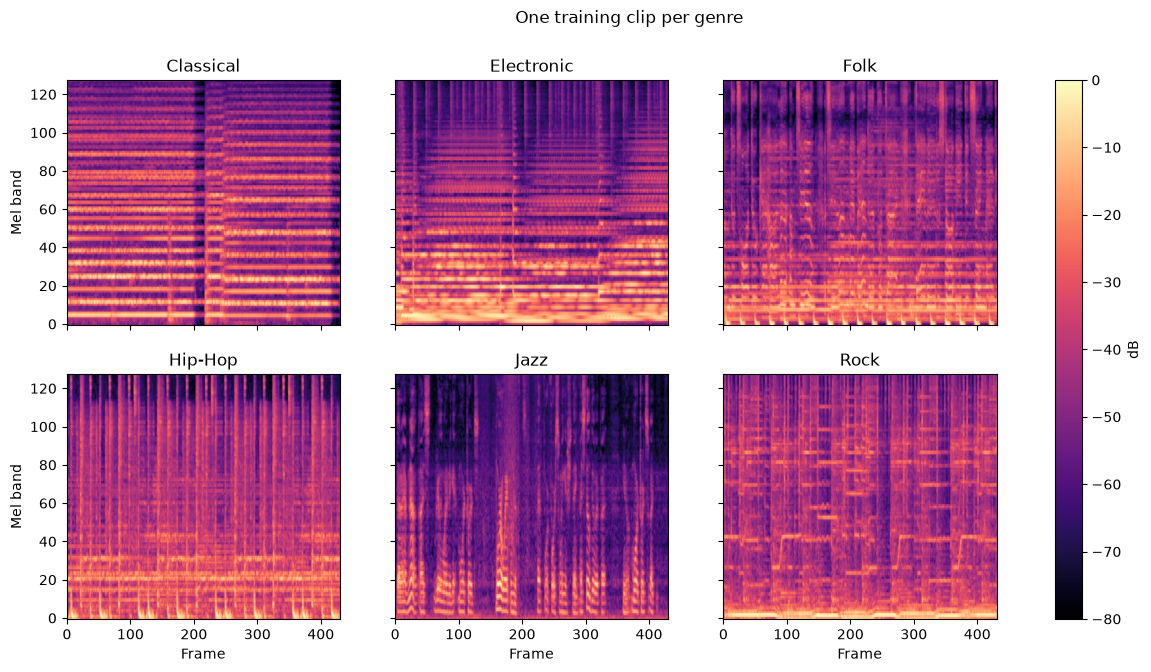

In [2]:
examples = train_idx.groupby("genre").head(1).sort_values("genre")
specs = load_spectrograms(examples["path"])
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for ax, g, s in zip(axes.flat, examples["genre"], specs):
    im = ax.imshow(s, origin="lower", aspect="auto", cmap="magma", vmin=-80, vmax=0)
    ax.set_title(g)
for ax in axes[1]: ax.set_xlabel("Frame")
for ax in axes[:, 0]: ax.set_ylabel("Mel band")
fig.colorbar(im, ax=axes, label="dB")
fig.suptitle("One training clip per genre")
fig.savefig(FIGURES / "spec_examples.png", dpi=200)
specs.shape

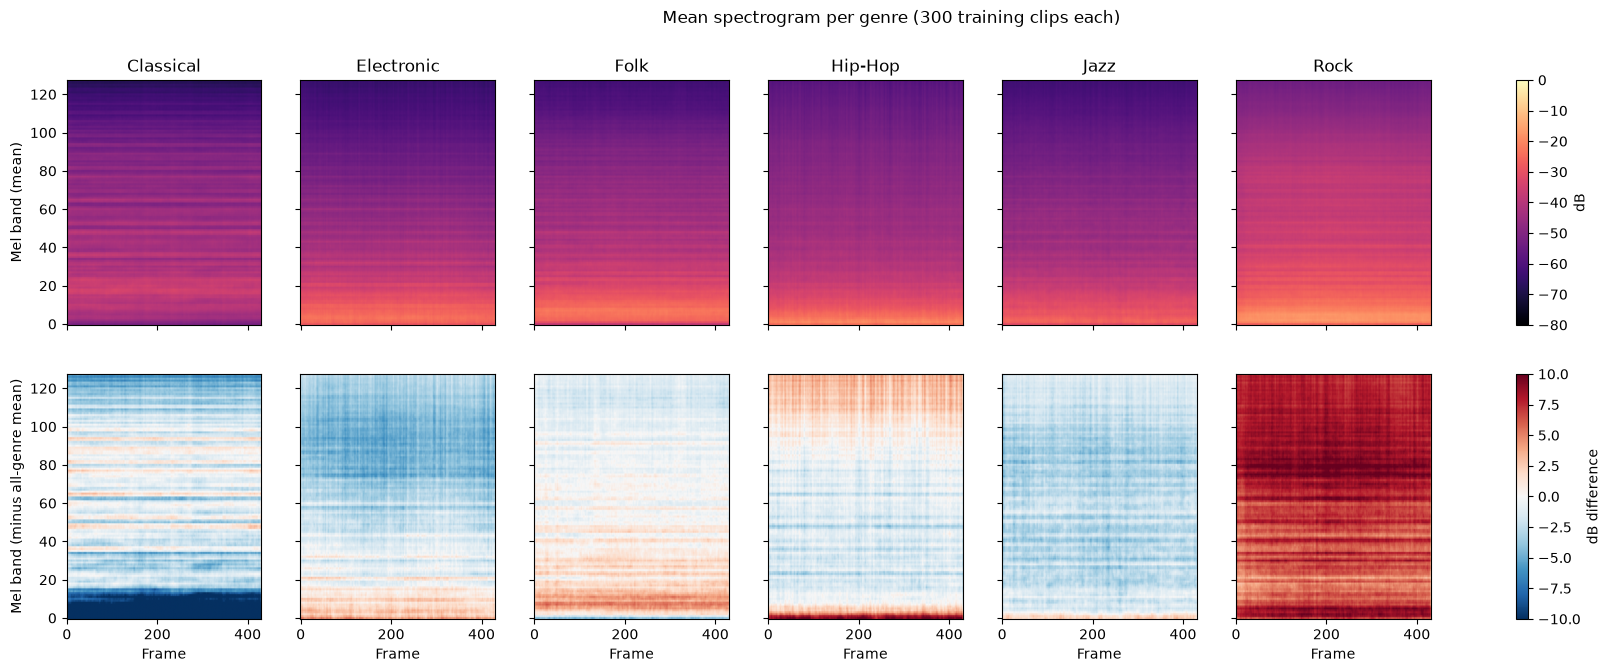

In [3]:
# Mean over up to 300 training clips per genre. Row 2 subtracts the all-genre mean, because the raw means look alike.
means = {g: load_spectrograms(train_idx[train_idx["genre"] == g]["path"].head(300)).mean(0) for g in genres}
overall = np.mean(list(means.values()), axis=0)
fig, axes = plt.subplots(2, 6, figsize=(22, 7), sharex=True, sharey=True)
for j, g in enumerate(genres):
    a = axes[0, j].imshow(means[g], origin="lower", aspect="auto", cmap="magma", vmin=-80, vmax=0)
    d = axes[1, j].imshow(means[g] - overall, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-10, vmax=10)
    axes[0, j].set_title(g)
    axes[1, j].set_xlabel("Frame")
axes[0, 0].set_ylabel("Mel band (mean)")
axes[1, 0].set_ylabel("Mel band (minus all-genre mean)")
fig.colorbar(a, ax=axes[0], label="dB")
fig.colorbar(d, ax=axes[1], label="dB difference")
fig.suptitle("Mean spectrogram per genre (300 training clips each)")
fig.savefig(FIGURES / "spec_mean_per_genre.png", dpi=200)

## 2. Value distribution and normalisation

min                              -80.0000
max                                0.0000
mean                             -44.4417
std                               16.6609
share of values at -80 (floor)     0.0328
share of clips whose max is 0      1.0000
dtype: float64

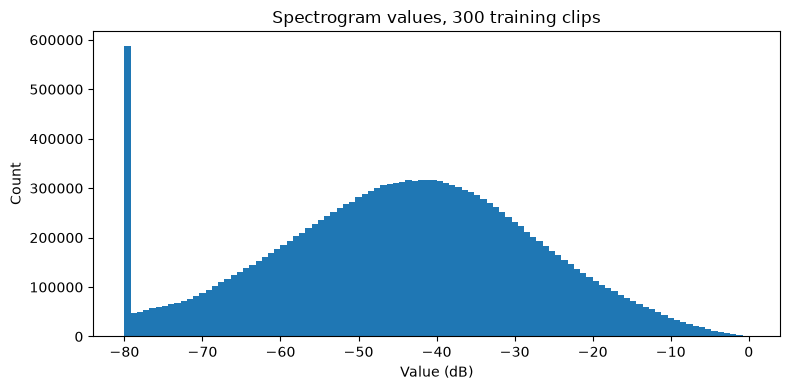

In [4]:
sample = load_spectrograms(train_idx.sample(300, random_state=SEED)["path"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sample.ravel(), bins=100)
ax.set(xlabel="Value (dB)", ylabel="Count", title="Spectrogram values, 300 training clips")
fig.tight_layout()
fig.savefig(FIGURES / "spec_value_hist.png", dpi=200)
pd.Series({"min": sample.min(), "max": sample.max(), "mean": sample.mean(), "std": sample.std(),
           "share of values at -80 (floor)": (sample == -80).mean(),
           "share of clips whose max is 0": (sample.max(axis=(1, 2)) == 0).mean()}).round(4)

Every value lies in [-80, 0] and every clip peaks at exactly 0. That is the signature of `librosa.power_to_db(S, ref=np.max, top_db=80)`: decibels relative to each clip's loudest bin, clipped 80 dB below it. So the data is already log-scaled and loudness-normalised per clip.

**Normalisation for the CNN:** standardise each mel band with its mean and std over all training clips and frames. Low bands are much louder than high bands on average, so one global mean/std would leave the high bands near-constant; per-band statistics put every band on the same scale while keeping differences between clips. Statistics come from training only, so validation and test stay unseen.

## 3. Leakage check

### Id patterns

In [5]:
n = idx["id"].str.extract(r"(\d+)", expand=False).astype(int)
order = idx.assign(n=n).sort_values("n")
same = (order["genre"].to_numpy()[1:] == order["genre"].to_numpy()[:-1]).mean()
print(f"ids run from {n.min()} to {n.max()} with {n.max() + 1 - len(idx)} gaps")
print(f"neighbouring ids share a genre {same:.3f} of the time (chance = {1 / len(genres):.3f})")
order[["id", "genre", "split"]].head(8)

ids run from 0 to 17381 with 0 gaps
neighbouring ids share a genre 0.169 of the time (chance = 0.167)


,id,genre,split
11588,clip00000,Jazz,training
5794,clip00001,Folk,training
8691,clip00002,Hip-Hop,training
2897,clip00003,Electronic,validation
0,clip00004,Classical,training
5795,clip00005,Folk,test
14485,clip00006,Rock,training
1,clip00007,Classical,validation


If the dataset had been cut from songs in order, neighbouring ids would mostly share a genre. They share it at chance level, so the ids were shuffled and carry no song information. Clips from the same song therefore cannot be grouped, and a random split may put segments of one song in both training and test. This is a limitation we cannot fix from the data.

### Exact duplicates, and the cached summary features

One pass over all 17,382 clips computes an md5 hash of each array's bytes and the 256 summary features (per-band mean and std over time). Both are cached to `data/processed/spec_summary.npz`, so later runs skip the pass.

In [6]:
cache = PROCESSED / "spec_summary.npz"
if cache.exists():
    z = np.load(cache, allow_pickle=True)
    assert (z["ids"] == idx["id"].to_numpy()).all(), "index changed; delete spec_summary.npz and rerun"
    X_all, md5 = z["X"], z["md5"]
else:
    X_all, md5 = np.empty((len(idx), 256), "float32"), []
    for start in range(0, len(idx), 500):  # batches of 500 clips (~110 MB)
        batch = load_spectrograms(idx["path"].iloc[start:start + 500])
        # Summary over time: each band's mean (spectral shape) and std (how much it varies).
        X_all[start:start + len(batch)] = np.hstack([batch.mean(axis=2), batch.std(axis=2)])
        md5 += [hashlib.md5(a.tobytes()).hexdigest() for a in batch]
    md5 = np.array(md5)
    np.savez(cache, ids=idx["id"].to_numpy(), X=X_all, md5=md5)

groups = idx.assign(md5=md5)[pd.Series(md5).duplicated(keep=False).to_numpy()]
cross = groups.groupby("md5")["split"].nunique() > 1
pd.Series({"clips in duplicate groups": len(groups), "duplicate groups": groups["md5"].nunique(),
           "groups spanning splits": int(cross.sum()),
           "groups with conflicting genres": int((groups.groupby("md5")["genre"].nunique() > 1).sum())})

clips in duplicate groups         0
duplicate groups                  0
groups spanning splits            0
groups with conflicting genres    0
dtype: int64

Exact duplicates that span splits would inflate test scores, because the model would be scored on clips it trained on. The counts above say whether that happens here. Exact hashing cannot catch overlapping or re-encoded segments of the same song, so the id limitation above still stands.

## 4. Summary-feature baseline: logistic regression

256 features per clip (128 band means, 128 band stds). This is the conventional model the CNN is compared against (H3): same spectrograms, but the time axis is collapsed, so local time-frequency patterns are lost.

In [7]:
part = lambda s: (X_all[(idx["split"] == s).to_numpy()], idx.loc[idx["split"] == s, "genre"])
X_train, y_train = part("training")
X_val, y_val = part("validation")
X_test, y_test = part("test")

gs = GridSearchCV(Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=2000, random_state=SEED))]),
                  {"model__C": np.logspace(-4, 2, 7)}, scoring="f1_macro",
                  cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1, return_train_score=True)
gs.fit(X_train, y_train)
pd.DataFrame(gs.cv_results_)[["param_model__C", "mean_train_score", "mean_test_score", "std_test_score"]].round(4)

,param_model__C,mean_train_score,mean_test_score,std_test_score
0,0.0001,0.5429,0.5397,0.0048
1,0.0010,0.6337,0.6235,0.0020
2,0.0100,0.7150,0.6920,0.0132
3,0.1000,0.7607,0.7267,0.0144
4,1.0000,0.7761,0.7340,0.0124
5,10.0000,0.7777,0.7316,0.0123
6,100.0000,0.7777,0.7315,0.0124


validation {'accuracy': 0.7342, 'macro_precision': 0.7331, 'macro_recall': 0.7342, 'macro_f1': 0.7326, 'macro_fpr': 0.0532, 'mcc': 0.6814, 'macro_auc_ovr': 0.9346}
test {'accuracy': 0.7473, 'macro_precision': 0.7448, 'macro_recall': 0.7473, 'macro_f1': 0.7454, 'macro_fpr': 0.0505, 'mcc': 0.697, 'macro_auc_ovr': 0.9403}


,precision,recall_tpr,fpr,f1,support
Jazz,0.6338,0.5770,0.0667,0.6041,435
Electronic,0.6998,0.6659,0.0570,0.6824,434
Folk,0.7535,0.7379,0.0483,0.7456,435
Rock,0.7810,0.7972,0.0446,0.7891,434
Hip-Hop,0.7229,0.7977,0.0612,0.7585,435
Classical,0.8778,0.9080,0.0253,0.8927,435


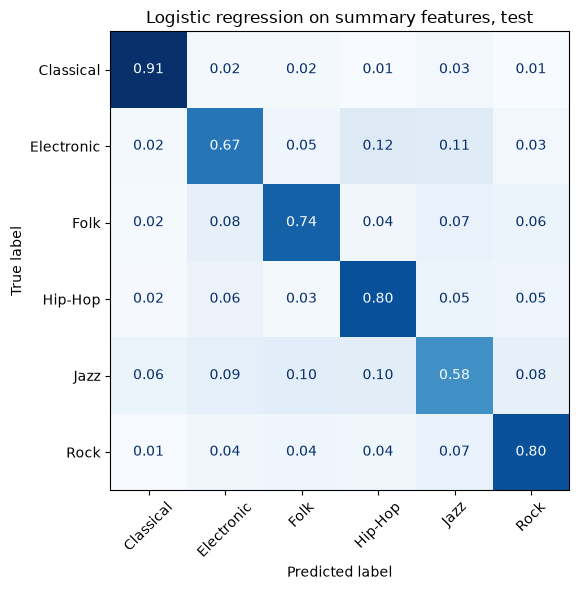

In [8]:
params = {"C": float(gs.best_params_["model__C"])}
for split, X, y in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    m, per_class = evaluate(y, gs.predict(X), gs.predict_proba(X), labels=gs.classes_)
    save_result("logreg_summary" if split == "test" else "logreg_summary_val", "spec", m, params=params, split=split)
    print(split, m)
fig = plot_confusion(y_test, gs.predict(X_test), labels=gs.classes_, title="Logistic regression on summary features, test")
fig.savefig(FIGURES / "spec_logreg_confusion.png", dpi=200)
per_class.sort_values("recall_tpr")

## Findings

- **Class balance:** 6 genres with 2,897 clips each, split 12,167 / 2,607 / 2,608 (2,027–2,028 training, 434–435 validation and 434–435 test per genre). The classes are balanced in every split, so accuracy and macro-F1 tell the same story and no resampling is needed.
- **Values and normalisation:** every value lies between −80 and 0 dB (mean −44.4, std 16.7), 3.3% of values sit on the −80 dB floor, and every clip peaks at exactly 0 dB. This matches `power_to_db(ref=max, top_db=80)`: the data is already log-scaled and normalised to each clip's peak. Low mel bands average around −25 dB and the highest around −65 dB, so for the CNN we standardise each band with its mean and std over training clips and frames. One global mean/std would leave the high bands nearly constant.
- **Mean spectrograms:** Rock is louder than average across almost every band (up to about +10 dB). Classical is much quieter in the lowest bands (about bands 0–15). Hip-Hop is strongest in the lowest few bands (bass) and slightly above average at the top. Electronic is quieter in the upper-middle bands (about 70–110), Folk is slightly louder in the low-to-middle bands, and Jazz is slightly below average across the middle. These differences hold across the whole clip rather than changing over time, which is why per-band means and stds already separate the genres well.
- **Leakage:** clip ids run from 0 to 17,381 with no gaps, and neighbouring ids share a genre 16.9% of the time against 16.7% by chance, so the ids are shuffled and carry no song information. Hashing all 17,382 arrays found 0 exact duplicates, so no identical clip appears in two splits. Clips cut from the same song cannot be identified, though, so segments of one song may sit in both training and test and the test scores may be optimistic. This affects the summary baseline and the CNN equally, so their comparison (H3) stays fair.
- **Logistic regression on 256 summary features:** CV macro-F1 rises from 0.540 at C = 1e-4 to 0.734 at C = 1 and is flat beyond that, so C = 1 was chosen. The training score is only about 0.04 above CV, so there is little overfitting. Validation macro-F1 was 0.733. On test it reached 0.745 macro-F1, 0.747 accuracy, 0.697 MCC and 0.940 macro-AUC, against ZeroR's 0.048 macro-F1 and 0.167 accuracy.
- **Per-genre results:** Classical is easiest (recall 0.91) and Jazz hardest (0.58), followed by Electronic (0.67). Jazz errors are spread across every other genre, mostly Folk and Hip-Hop (10% each). Electronic is confused with Hip-Hop (12%) and Jazz (11%). These are the genres a CNN that keeps time-frequency structure should improve most (H3).